# Utilizando Stable Diffusion desde Hugging Face

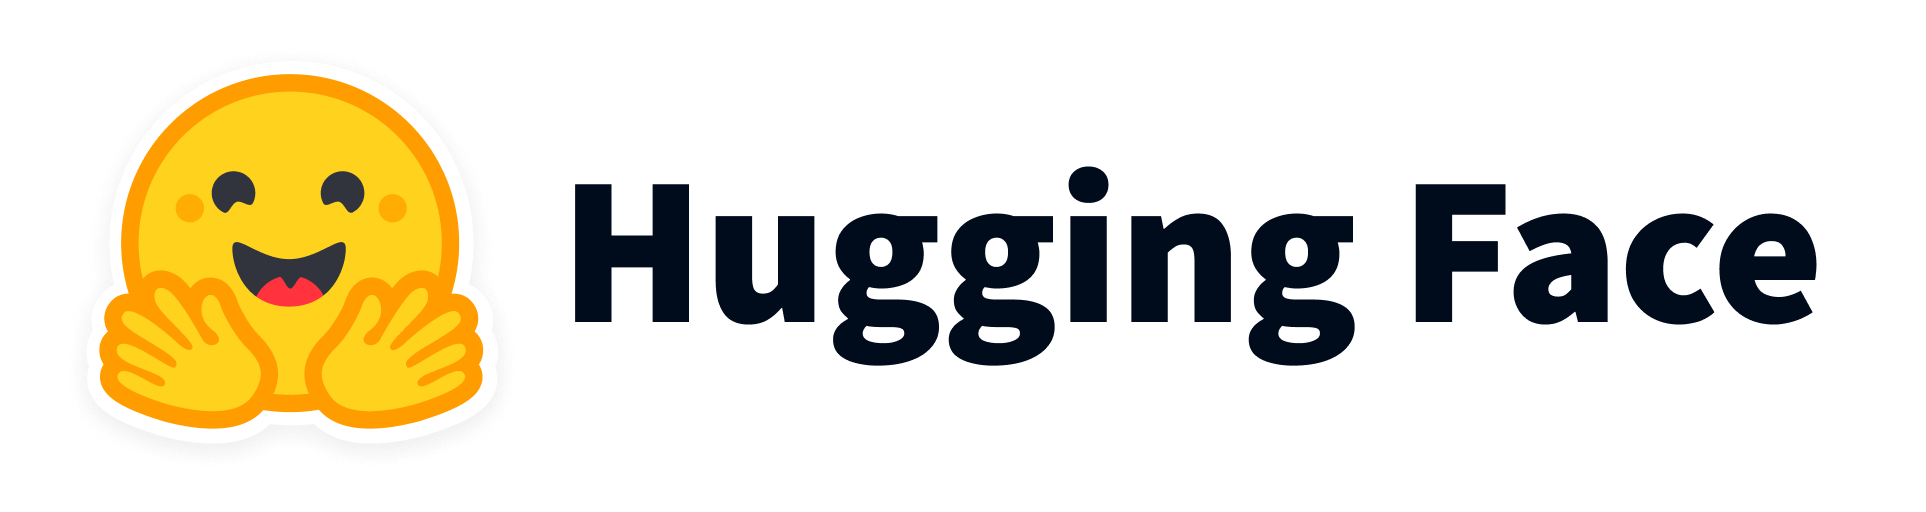

version 1.0

## 0. Instalación de las librerías necesarias

In [1]:
!pip install diffusers
!pip install transformers
!pip install torch
!pip install accelerate
!pip install opencv-contrib-python

In [2]:
!nvidia-smi

Thu Jul 10 16:50:30 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Text-to-Image con modelos de HuggingFace:
Lista con los modelos Text-to-Image disponibles: https://huggingface.co/models?pipeline_tag=text-to-image&sort=downloads<br>

Lista con todos los Stable Diffusion Pipelines: https://huggingface.co/docs/diffusers/api/pipelines/stable_diffusion/overview

AutoPipeline documentación: https://huggingface.co/docs/diffusers/tutorials/autopipeline#autopipeline

In [3]:
from diffusers import StableDiffusionPipeline, StableDiffusionXLPipeline
from diffusers import AutoPipelineForText2Image
import matplotlib.pyplot as plt
import torch

model_id1 = "dreamlike-art/dreamlike-diffusion-1.0"
model_id2 = "stabilityai/stable-diffusion-xl-base-1.0"
model_id3 = "stabilityai/sdxl-turbo"
model_id4 = "stabilityai/stable-diffusion-2-1"
model_id5 = "CompVis/stable-diffusion-v1-4"
model_id6 = "madebyollin/taesd"
model_id7 = "kandinsky-community/kandinsky-2-2-decoder"

model_id = model_id1

In [4]:
# Vaciar la memoria de la GPU:
torch.cuda.empty_cache()

In [5]:
pipe32 = AutoPipelineForText2Image.from_pretrained(
    pretrained_model_or_path=model_id,
    torch_dtype=torch.float32,
    use_safetensors=True
) # safetensors es simplemente un formato en el que se ha guardado el modelo

# Si tenemos GPU alojamos ahi el modelo para acelerar la generacion:
if torch.cuda.is_available():
  pipe32 = pipe32.to("cuda")

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

In [6]:
print(f"El modelo en float32 ocupa en GPU: {torch.cuda.memory_allocated() / 1e6:.2f} MB")
del pipe32

# Limpiamos la GPU:
torch.cuda.empty_cache()

El modelo en float32 ocupa en GPU: 4291.78 MB


In [7]:
pipe16 = AutoPipelineForText2Image.from_pretrained(
    pretrained_model_or_path=model_id,
    torch_dtype=torch.float16,
    use_safetensors=True
)
if torch.cuda.is_available():
  pipe16 = pipe16.to("cuda")

print(f"El modelo en float16 ocupa en GPU: {torch.cuda.memory_allocated() / 1e6:.2f} MB")

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

El modelo en float16 ocupa en GPU: 2156.44 MB


In [8]:
pipe = pipe16

In [9]:
pipe

StableDiffusionPipeline {
  "_class_name": "StableDiffusionPipeline",
  "_diffusers_version": "0.34.0",
  "_name_or_path": "dreamlike-art/dreamlike-diffusion-1.0",
  "feature_extractor": [
    null,
    null
  ],
  "image_encoder": [
    null,
    null
  ],
  "requires_safety_checker": null,
  "safety_checker": [
    null,
    null
  ],
  "scheduler": [
    "diffusers",
    "DDIMScheduler"
  ],
  "text_encoder": [
    "transformers",
    "CLIPTextModel"
  ],
  "tokenizer": [
    "transformers",
    "CLIPTokenizer"
  ],
  "unet": [
    "diffusers",
    "UNet2DConditionModel"
  ],
  "vae": [
    "diffusers",
    "AutoencoderKL"
  ]
}

In [23]:
prompt = """
Ruins of a futuristic city overtaken by nature, giant broken robots half-buried in moss, a lone wanderer with a cape walking among the rubble, dramatic clouds, atmospheric lighting, photorealistic, detailed textures, dreamlike tone
"""

In [24]:
image = pipe(
    prompt=prompt,
    num_inference_steps=50,
)

  0%|          | 0/50 [00:00<?, ?it/s]

otros parámetros disponibles cuando llamamos al pipeline: https://github.com/huggingface/diffusers/blob/v0.28.2/src/diffusers/pipelines/stable_diffusion/pipeline_stable_diffusion.py#L753

¿Qué es el "guidance_scale"?

- Cuánto se fuerza al modelo a seguir el prompt.

No confundir con "prompt_strenght", que se usa solo en casos de Image To Image.

In [25]:
my_image = image.images[0]

[PROMPT]:  
Ruins of a futuristic city overtaken by nature, giant broken robots half-buried in moss, a lone wanderer with a cape walking among the rubble, dramatic clouds, atmospheric lighting, photorealistic, detailed textures, dreamlike tone



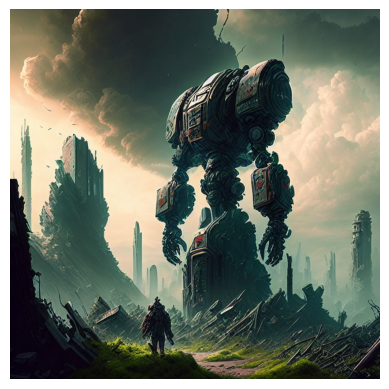

In [26]:
print("[PROMPT]: ",prompt)
plt.imshow(my_image);
plt.axis('off');

Probamos más ejemplos:

  0%|          | 0/50 [00:00<?, ?it/s]

[PROMPT]:  
Futuristic cyberpunk city at night, neon lights reflecting off rainy streets, flying cars in the sky, dense fog, anime-style characters walking with umbrellas, Blade Runner vibes, highly detailed, cinematic composition, 4k



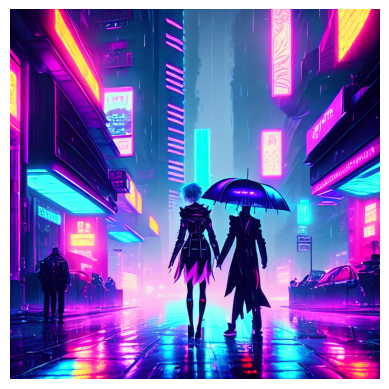

In [18]:
prompt = """
Futuristic cyberpunk city at night, neon lights reflecting off rainy streets, flying cars in the sky, dense fog, anime-style characters walking with umbrellas, Blade Runner vibes, highly detailed, cinematic composition, 4k
"""
image = pipe(prompt)
my_image=image.images[0]

print("[PROMPT]: ",prompt)
plt.imshow(my_image);
plt.axis('off');

  0%|          | 0/50 [00:00<?, ?it/s]

[PROMPT]:  
8k intricate, highly detailed, digital photography, best quality, masterpiece, a full-body photo of a warrior girl. Torn clothes exposing parts of her body, scratch marks, epic, hyperrealistic, hyperrealism, 8k, cinematic lighting, Greg Rutkowski, WLOP



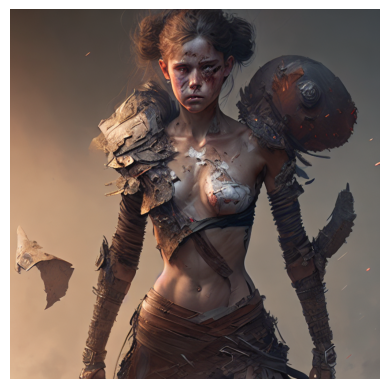

In [16]:
prompt = """
8k intricate, highly detailed, digital photography, best quality, masterpiece, a full-body photo of a warrior girl. Torn clothes exposing parts of her body, scratch marks, epic, hyperrealistic, hyperrealism, 8k, cinematic lighting, Greg Rutkowski, WLOP
"""
image = pipe(prompt)
my_image=image.images[0]

print("[PROMPT]: ",prompt)
plt.imshow(my_image);
plt.axis('off');

  0%|          | 0/50 [00:00<?, ?it/s]

[PROMPT]:  
a sunny landscape in the mountains



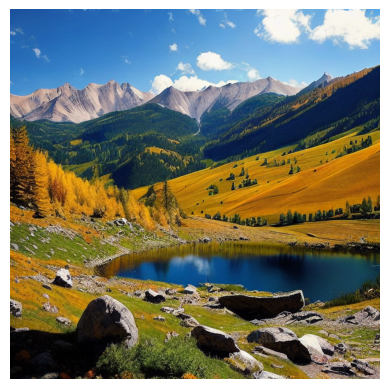

In [17]:
prompt = """
a sunny landscape in the mountains
"""
image = pipe(prompt)
my_image=image.images[0]

print("[PROMPT]: ",prompt)
plt.imshow(my_image);
plt.axis('off');

## 2. ControlNet Pipeline con StableDiffusion

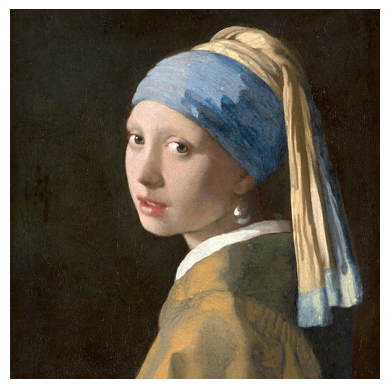

In [28]:
from diffusers import StableDiffusionControlNetPipeline
from diffusers.utils import load_image
import matplotlib.pyplot as plt

# Primero descargamos una imagen para extraer su contorno:  # en este caso, "La joven de la Perla"
image = load_image(
    "https://hf.co/datasets/huggingface/documentation-images/resolve/main/diffusers/input_image_vermeer.png"
)

plt.imshow(image);
plt.axis('off');

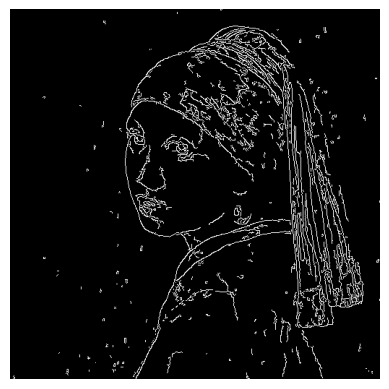

In [29]:
import cv2
from PIL import Image
import numpy as np

image = np.array(image)

low_threshold = 100
high_threshold = 200  # son threshold para el algoritmo de CannyEdges

image = cv2.Canny(image, low_threshold, high_threshold)
image = image[:, :, None]  # el algoritmo CannyEdges solo devuelve 1 canal en blanco y negro, por lo que añadimos una dimension mas al array
image = np.concatenate([image, image, image], axis=2)  # y posteriormente concatenamos 3 canales para generar la imagen definitiva
canny_image = Image.fromarray(image)

plt.imshow(canny_image);
plt.axis('off');

In [30]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel
import torch

controlnet = ControlNetModel.from_pretrained(
    pretrained_model_name_or_path="lllyasviel/sd-controlnet-canny",
    torch_dtype=torch.float16
)

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    pretrained_model_name_or_path="runwayml/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float16
)

if torch.cuda.is_available():
  pipe.to("cuda")

config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.45G [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

...

vocab.json: 0.00B [00:00, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

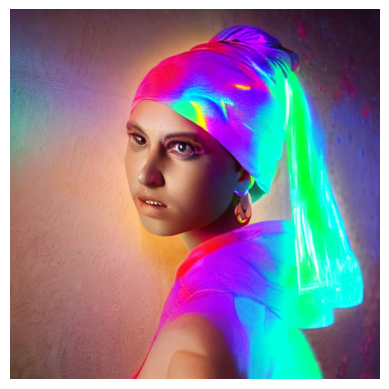

In [31]:
out_image = pipe(
    prompt="A modern young girl in a futuristic cyberpunk style, vibrant neon lighting, holographic fabrics on the turban, glowing earring, dark urban background, cinematic lighting --v 5 --ar 2:3",
    num_inference_steps=50,
    image=canny_image
).images[0]

plt.imshow(out_image);
plt.axis('off');

## 3. Image-to-Image pipeline con StableDiffusion

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

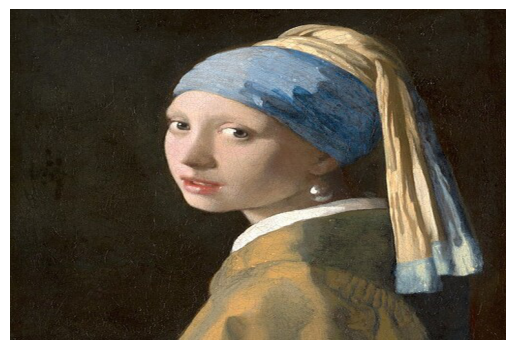

In [33]:
import torch
from diffusers import StableDiffusionImg2ImgPipeline

torch.cuda.empty_cache()

model_id = "runwayml/stable-diffusion-v1-5"
pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    pretrained_model_name_or_path=model_id,
    torch_dtype=torch.float16
)

if torch.cuda.is_available():
  pipe = pipe.to("cuda")

init_image = load_image(
    "https://hf.co/datasets/huggingface/documentation-images/resolve/main/diffusers/input_image_vermeer.png"
)

init_image = init_image.resize((768, 512))
plt.imshow(init_image);
plt.axis('off');

  0%|          | 0/37 [00:00<?, ?it/s]

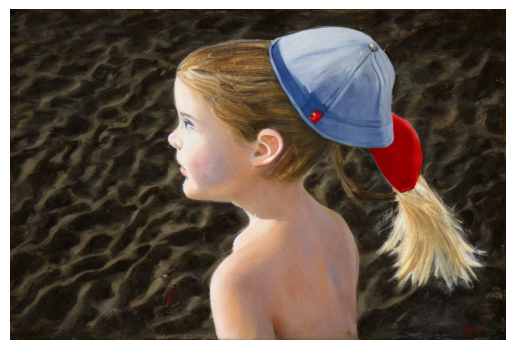

In [40]:
out_image = pipe(
    prompt="young girl with red hat in the beach",
    image=init_image,
    strength=0.75,
).images[0]

plt.imshow(out_image);
plt.axis('off');